ORIGINAL BIOLOGICAL DATASET


,Sample_ID,Organism,Gene_Expression,GC_Content_Percent
0,S01,Human,12.5,45.2
1,S02,Mouse,15.2,42.8
2,S03,Human,NaN,46.1
3,S04,Zebrafish,9.8,NaN
4,S05,Mouse,14.1,43.5
5,S05,Mouse,14.1,43.5



DATASET INFORMATION
Number of rows: 6
Number of columns: 4

MISSING VALUES
Sample_ID             0
Organism              0
Gene_Expression       1
GC_Content_Percent    1
dtype: int64

CLEANED DATASET


,Sample_ID,Organism,Gene_Expression,GC_Content_Percent
0,S01,Human,12.5,45.20
1,S02,Mouse,15.2,42.80
2,S03,Human,13.3,46.10
3,S04,Zebrafish,9.8,44.35
4,S05,Mouse,14.1,43.50



STATISTICAL SUMMARY


,Gene_Expression,GC_Content_Percent
count,5.000000,5.000000
mean,12.980000,44.390000
std,2.038872,1.313583
min,9.800000,42.800000
25%,12.500000,43.500000
50%,13.300000,44.350000
75%,14.100000,45.200000
max,15.200000,46.100000



ORGANISM DISTRIBUTION
Organism
Human        2
Mouse        2
Zebrafish    1
Name: count, dtype: int64


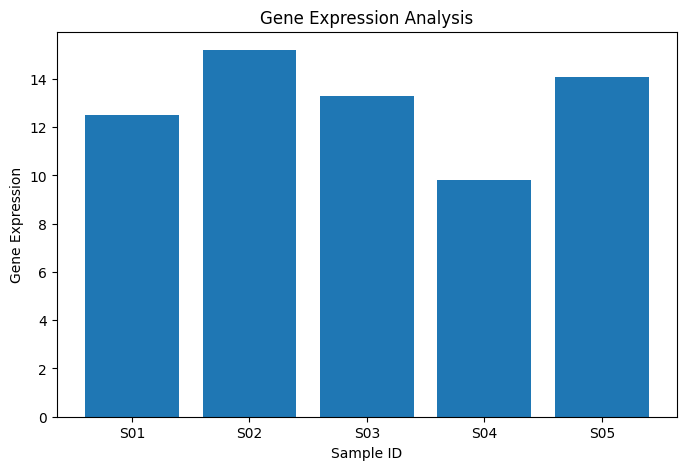

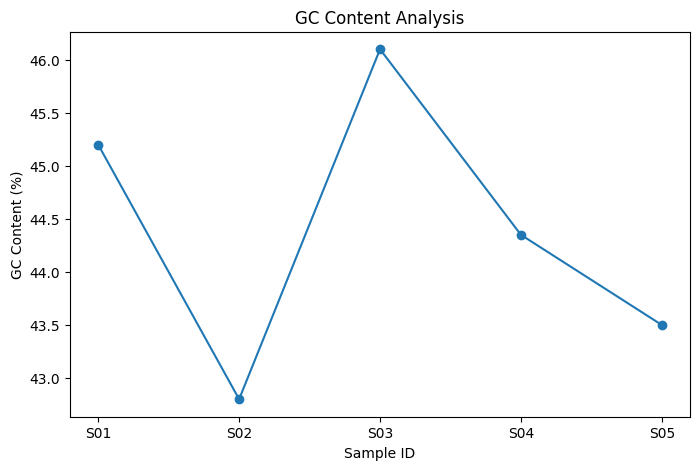


FINAL DATA VALIDATION
Missing values: 0
Duplicate rows: 0

SUCCESS! All analysis completed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# SWYNEX - Task 4: Final Bioinformatics Report

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create sample biological dataset
data = {
    "Sample_ID": ["S01", "S02", "S03", "S04", "S05", "S05"],
    "Organism": ["Human", "Mouse", "Human", "Zebrafish", "Mouse", "Mouse"],
    "Gene_Expression": [12.5, 15.2, None, 9.8, 14.1, 14.1],
    "GC_Content_Percent": [45.2, 42.8, 46.1, None, 43.5, 43.5]
}

df = pd.DataFrame(data)

print("ORIGINAL BIOLOGICAL DATASET")
display(df)

# 2. Dataset information
print("\nDATASET INFORMATION")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 3. Identify missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 4. Remove duplicate records
df_clean = df.drop_duplicates().copy()

# 5. Handle missing numerical values
numeric_columns = df_clean.select_dtypes(
    include="number"
).columns

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# 6. Display cleaned dataset
print("\nCLEANED DATASET")
display(df_clean)

# 7. Statistical analysis
print("\nSTATISTICAL SUMMARY")
display(df_clean.describe())

# 8. Organism count
print("\nORGANISM DISTRIBUTION")
print(df_clean["Organism"].value_counts())

# 9. Gene expression visualization
plt.figure(figsize=(8, 5))
plt.bar(df_clean["Sample_ID"], df_clean["Gene_Expression"])
plt.title("Gene Expression Analysis")
plt.xlabel("Sample ID")
plt.ylabel("Gene Expression")
plt.show()

# 10. GC content visualization
plt.figure(figsize=(8, 5))
plt.plot(
    df_clean["Sample_ID"],
    df_clean["GC_Content_Percent"],
    marker="o"
)
plt.title("GC Content Analysis")
plt.xlabel("Sample ID")
plt.ylabel("GC Content (%)")
plt.show()

# 11. Verify cleaned dataset
print("\nFINAL DATA VALIDATION")
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

# 12. Save cleaned dataset
df_clean.to_csv(
    "SWYNEX_cleaned_biological_dataset.csv",
    index=False
)

# 13. Save statistical summary
df_clean.describe().to_csv(
    "SWYNEX_statistical_summary.csv"
)

print("\nSUCCESS! All analysis completed.")

# 14. Download output files
from google.colab import files

files.download("SWYNEX_cleaned_biological_dataset.csv")
files.download("SWYNEX_statistical_summary.csv")
